In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from dask.diagnostics import ProgressBar
import cftime
from datetime import datetime


In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
# Enable Dask progress bar for monitoring
ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

compute_climatology = False
ds_clims = []

if compute_climatology:
    for experiment in experiments:
        print(f"Processing experiment: {experiment}")
        
        # Open dataset with Dask and process in chunks
        ds = xr.open_mfdataset(
            f'{base_path}/{experiment}/falwa_vars/*.nc',
            combine='by_coords',
            parallel=True,
            chunks={'time': 30}  # Process one month at a time (30 days)
        )
        print('Data imported')

        # Compute means in one step to reduce overhead
        ds_mean = ds[['ucomp', 'vcomp', 'temp']].mean('time')
        ds_stds = ds[['ucomp', 'vcomp', 'temp']].std('time')
        ds_stds = ds_stds.rename({'ucomp': 'ucomp_std', 'vcomp': 'vcomp_std', 'temp': 'temp_std'})
        # Merge the two datasets
        ds_mean = xr.merge([ds_mean, ds_stds], compat='override')
        print('Means and std computed')

        # Save the climatology to NetCDF
        ds_mean.to_netcdf(f'{base_path}/{experiment}/tot/uvt_clim_2-51.nc')
        print('Climatology saved')
        ds.close()
        ds_clims.append(ds_mean)
else:
    for experiment in experiments:
        ds_clims.append(xr.open_dataset(f'{base_path}/{experiment}/tot/uvt_clim_2-51.nc'))

In [4]:
for i,ds in enumerate(ds_clims):
  #add the time dimension to the dataset
  ds = ds.expand_dims(dim={'time':[datetime(1, 1, 1)]})
  #flip and append the southern hemisphere data and then average along time
  ds = flip_and_append(ds).mean('time')
  ds_clims[i] = ds

In [5]:
ds

<xarray.Dataset> Size: 4MB
Dimensions:  (pfull: 20, lat: 61, lon: 240)
Coordinates:
  * lon      (lon) float64 2kB -180.0 -178.5 -177.0 -175.5 ... 175.5 177.0 178.5
  * lat      (lat) float64 488B 0.0 1.5 3.0 4.5 6.0 ... 84.0 85.5 87.0 88.5 90.0
  * pfull    (pfull) float32 80B 1e+03 950.0 900.0 850.0 ... 150.0 100.0 50.0
Data variables:
    ucomp    (pfull, lat, lon) float32 1MB -1.956 -1.96 -1.959 ... -1.125 -1.125
    vcomp    (pfull, lat, lon) float32 1MB 0.04665 0.04962 ... -0.003172
    temp     (pfull, lat, lon) float32 1MB 300.6 300.6 300.6 ... 231.5 231.5

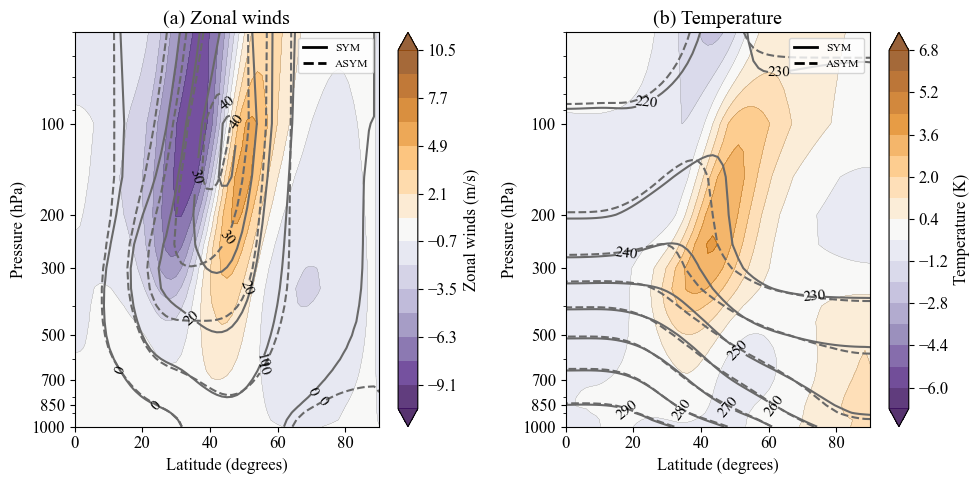

In [9]:
from matplotlib.lines import Line2D  # <-- Add this import at the top of your cell

# Set global font family and size
plt.rcParams['font.family'] = 'Times New Roman'      # e.g., 'serif', 'sans-serif', 'monospace'
plt.rcParams['font.size'] = 12             # default font size

# initialize a 2 axis plot
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# plot the ucomp zonal mean contours for baseline st and baseline experiments on the first axis
levels = np.arange(-10,50,10)#np.linspace(-10, 40, 8)
levels_diff = np.arange(-10.5,11,1.4)

shad = axs[0].contourf(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['ucomp'].mean('lon')-ds_clims[0]['ucomp'].mean('lon'), levels=levels_diff, alpha=0.8, cmap='PuOr_r', extend='both')
axs[0].contour(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['ucomp'].mean('lon')-ds_clims[0]['ucomp'].mean('lon'), levels=levels_diff, colors='k',linewidths=0.1,negative_linestyles='solid')

c1 = axs[0].contour(ds_clims[0]['lat'], ds_clims[0]['pfull'], ds_clims[0]['ucomp'].mean('lon'),levels=levels, colors = 'dimgray',alpha= 1,linewidths=1.5,linestyles='dashed')
axs[0].clabel(c1, inline=True, colors='black', inline_spacing = 1,rightside_up=True ,fontsize=11)
c2 = axs[0].contour(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['ucomp'].mean('lon'), levels=levels, colors = 'dimgray',alpha = 1,linewidths=1.5)
axs[0].clabel(c2, inline=True, colors='black', inline_spacing = 1,rightside_up=True ,fontsize=11)

axs[0].set_title('(a) Zonal winds')
axs[0].set_ylabel('Pressure (hPa)')
axs[0].set_xlabel('Latitude (degrees)') 
axs[0].invert_yaxis()
axs[0].set_yscale('log')
axs[0].set_yticks([1000, 850, 700, 500, 300, 200, 100])
axs[0].get_yaxis().set_major_formatter(plt.ScalarFormatter())

# Add legend

custom_lines = [
    Line2D([0], [0], color='black', lw=2, linestyle='solid', label='SYM'),
    Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='ASYM')
]
axs[0].legend(handles=custom_lines, loc='upper right',fontsize='x-small')

fig.colorbar(shad, ax=axs[0], orientation='vertical', label='Zonal winds (m/s)')

# plot the ucomp zonal mean contours for baseline st and baseline experiments on the first axis
levels = np.arange(200,300,10)#np.linspace(-10, 40, 8)
levels_diff = np.arange(-6.8,6.9,0.8)

shad = axs[1].contourf(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['temp'].mean('lon')-ds_clims[0]['temp'].mean('lon'), levels=levels_diff, alpha=0.8, cmap='PuOr_r', extend='both')
axs[1].contour(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['temp'].mean('lon')-ds_clims[0]['temp'].mean('lon'), levels=levels_diff, colors='k',linewidths=0.1,negative_linestyles='solid')

c1 = axs[1].contour(ds_clims[0]['lat'], ds_clims[0]['pfull'], ds_clims[0]['temp'].mean('lon'),levels=levels, colors = 'dimgray',alpha= 1,linewidths=1.5,linestyles='dashed')
#axs[1].clabel(c1, inline=True, inline_spacing = 1,rightside_up=True ,fontsize=11)
c2 = axs[1].contour(ds_clims[2]['lat'], ds_clims[2]['pfull'], ds_clims[2]['temp'].mean('lon'), levels=levels, colors = 'dimgray',alpha = 1,linewidths=1.5)
axs[1].clabel(c2, inline=True, colors = 'black', inline_spacing = 1,rightside_up=True ,fontsize=11)

axs[1].set_title('(b) Temperature')
axs[1].set_ylabel('Pressure (hPa)')
axs[1].set_xlabel('Latitude (degrees)') 
axs[1].invert_yaxis()
axs[1].set_yscale('log')
axs[1].set_yticks([1000, 850, 700, 500, 300, 200, 100])
axs[1].get_yaxis().set_major_formatter(plt.ScalarFormatter())

# Add legend

custom_lines = [
    Line2D([0], [0], color='black', lw=2, linestyle='solid', label='SYM'),
    Line2D([0], [0], color='black', lw=2, linestyle='dashed', label='ASYM')
]
axs[1].legend(handles=custom_lines, loc='upper right',fontsize='x-small')

fig.colorbar(shad, ax=axs[1], orientation='vertical', label='Temperature (K)')

plt.tight_layout()

plt.savefig('PLOTS/Figure1.png',dpi=300)
